In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

In [3]:
model_path = Path(
    "../models/tomato_disease_mobilenetv2_finetuned.keras"
)

model = tf.keras.models.load_model(model_path)

print("Model loaded successfully!")

Model loaded successfully!


In [4]:
dataset_path = Path(
    "../dataset/raw"
)

class_names = sorted([
    folder.name
    for folder in dataset_path.iterdir()
    if folder.is_dir()
])

print(class_names)

['Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']


In [5]:
project_path = Path.cwd()

print("Current Folder:", project_path)
print("Files and Folders:")

for item in project_path.iterdir():
    print(item.name)

Current Folder: c:\Users\mayak\OneDrive\Desktop\AgriVision-AI\notebooks
Files and Folders:
01_data_exploration.ipynb
02_image_Preprocessing.ipynb
03_cnn_model.ipynb
04_mobilenetv2_model.ipynb
05_fine_tuning.ipynb
06_prediction.ipynb


In [6]:
from pathlib import Path

project_path = Path.cwd().parent

dataset_path = project_path / "dataset" / "raw"

print("Dataset path:", dataset_path)
print("Exists:", dataset_path.exists())

Dataset path: c:\Users\mayak\OneDrive\Desktop\AgriVision-AI\dataset\raw
Exists: True


In [7]:
image_extensions = ["*.jpg", "*.JPG", "*.jpeg", "*.png"]

test_image = None

for folder in dataset_path.iterdir():
    if folder.is_dir():
        for ext in image_extensions:
            images = list(folder.glob(ext))
            if images:
                test_image = images[0]
                break
    if test_image:
        break

print("Test Image:", test_image)

Test Image: c:\Users\mayak\OneDrive\Desktop\AgriVision-AI\dataset\raw\Tomato_Bacterial_spot\00416648-be6e-4bd4-bc8d-82f43f8a7240___GCREC_Bact.Sp 3110.JPG


In [8]:
image_path = test_image

img = tf.keras.utils.load_img(
    image_path,
    target_size=(160, 160)
)

print("Image loaded successfully!")

Image loaded successfully!


In [9]:
img_array = tf.keras.utils.img_to_array(img)

img_array = np.expand_dims(img_array, axis=0)

img_array = tf.keras.applications.mobilenet_v2.preprocess_input(
    img_array
)

print("Processed Image Shape:", img_array.shape)

Processed Image Shape: (1, 160, 160, 3)


In [10]:
predictions = model.predict(img_array)

predicted_index = np.argmax(predictions[0])

predicted_class = class_names[predicted_index]

confidence = np.max(predictions[0]) * 100

print("Predicted Disease:", predicted_class)
print(f"Confidence: {confidence:.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 852ms/step
Predicted Disease: Tomato_Late_blight
Confidence: 92.58%


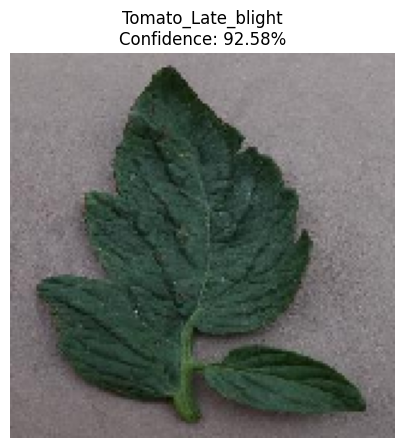

In [11]:
plt.figure(figsize=(5, 5))

plt.imshow(img)
plt.title(
    f"{predicted_class}\nConfidence: {confidence:.2f}%"
)
plt.axis("off")
plt.show()

In [12]:
probabilities = predictions[0]

for class_name, probability in zip(class_names, probabilities):
    print(f"{class_name}: {probability * 100:.2f}%")

Tomato_Bacterial_spot: 0.09%
Tomato_Early_blight: 6.34%
Tomato_Late_blight: 92.58%
Tomato_Leaf_Mold: 0.07%
Tomato_Septoria_leaf_spot: 0.01%
Tomato_Spider_mites_Two_spotted_spider_mite: 0.05%
Tomato__Target_Spot: 0.01%
Tomato__Tomato_YellowLeaf__Curl_Virus: 0.11%
Tomato__Tomato_mosaic_virus: 0.00%
Tomato_healthy: 0.74%


In [13]:
import pandas as pd

results = pd.DataFrame({
    "Disease": class_names,
    "Probability": predictions[0] * 100
})

results = results.sort_values(
    by="Probability",
    ascending=False
)

print(results)

                                       Disease  Probability
2                           Tomato_Late_blight    92.584396
1                          Tomato_Early_blight     6.337502
9                               Tomato_healthy     0.743134
7        Tomato__Tomato_YellowLeaf__Curl_Virus     0.108370
0                        Tomato_Bacterial_spot     0.090093
3                             Tomato_Leaf_Mold     0.070036
5  Tomato_Spider_mites_Two_spotted_spider_mite     0.050774
4                    Tomato_Septoria_leaf_spot     0.009236
6                          Tomato__Target_Spot     0.006263
8                  Tomato__Tomato_mosaic_virus     0.000195


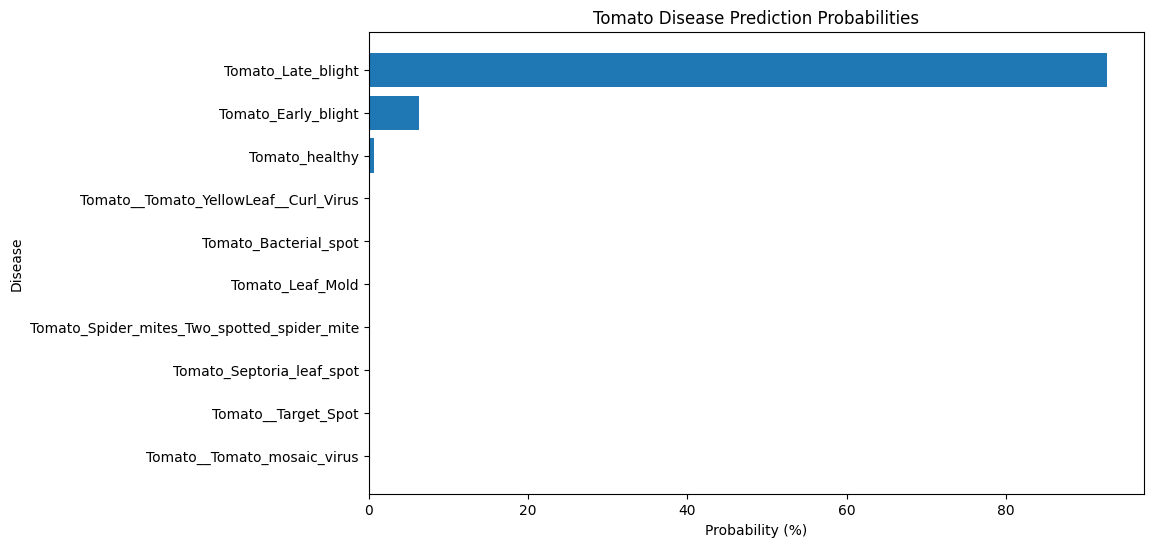

In [14]:
plt.figure(figsize=(10, 6))

plt.barh(
    results["Disease"],
    results["Probability"]
)

plt.xlabel("Probability (%)")
plt.ylabel("Disease")
plt.title("Tomato Disease Prediction Probabilities")
plt.gca().invert_yaxis()
plt.show()